# Reference Transmitter Offset Compensation

## Without Offset Compensation

In [1]:
!mkdir /home/florian/Downloads/dichasus
!wget --content-disposition https://darus.uni-stuttgart.de/api/access/datafile/:persistentId?persistentId=doi:10.18419/darus-2202/2 -P /home/florian/Downloads/dichasus # dichasus-0152

mkdir: cannot create directory ‘/home/florian/Downloads/dichasus’: File exists
--2021-11-25 18:12:20--  https://darus.uni-stuttgart.de/api/access/datafile/:persistentId?persistentId=doi:10.18419/darus-2202/2
SSL_INIT
Loaded CA certificate '/etc/ssl/certs/ca-certificates.crt'
Resolving darus.uni-stuttgart.de (darus.uni-stuttgart.de)... 2001:7c0:2041:17f::87, 129.69.7.87
Connecting to darus.uni-stuttgart.de (darus.uni-stuttgart.de)|2001:7c0:2041:17f::87|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://s3.tik.uni-stuttgart.de/fokus-dv-prod-2/10.18419/darus-2202/17c928fae7d-17334055e830?response-content-disposition=attachment%3B%20filename%2A%3DUTF-8%27%27dichasus-0152.tfrecords&response-content-type=application%2Foctet-stream&X-Amz-Algorithm=AWS4-HMAC-SHA256&X-Amz-Date=20211125T171221Z&X-Amz-SignedHeaders=host&X-Amz-Expires=172800&X-Amz-Credential=ZYFB5FYVYI021REQFP7K%2F20211125%2Fdataverse%2Fs3%2Faws4_request&X-Amz-Signature=4de20e2ac4900e177b53f

In [2]:
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import tensorflow as tf
import numpy as np
import json
%matplotlib inline

2021-11-25 18:21:43.761598: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2021-11-25 18:21:43.761625: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


### Loading the dataset

In [3]:
def record_parse_function(proto):
    record = tf.io.parse_single_example(proto, {
        "csi": tf.io.FixedLenFeature([], tf.string, default_value = ''),
        "pos-tachy": tf.io.FixedLenFeature([], tf.string, default_value = '')
    })

    csi = tf.io.parse_tensor(record["csi"], out_type = tf.float32)
    csi = tf.signal.fftshift(csi, axes = 1)
    csi = tf.complex(csi[:,:,0], csi[:,:,1])
    pos_tachy = tf.ensure_shape(tf.io.parse_tensor(record["pos-tachy"], out_type = tf.float64), (3))

    # We only care about x/y position dimensions, z is always close to 0
    return csi, pos_tachy[:2]

datafiles = ["/home/florian/Downloads/dichasus/dichasus-0152.tfrecords"]
dataset = tf.data.TFRecordDataset(datafiles).map(record_parse_function)
dataset = dataset.cache()

2021-11-25 18:21:45.062280: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcuda.so.1
2021-11-25 18:21:45.130479: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:937] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2021-11-25 18:21:45.130752: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1733] Found device 0 with properties: 
pciBusID: 0000:25:00.0 name: NVIDIA GeForce GT 1030 computeCapability: 6.1
coreClock: 1.5185GHz coreCount: 3 deviceMemorySize: 1.95GiB deviceMemoryBandwidth: 44.76GiB/s
2021-11-25 18:21:45.130931: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2021-11-25 18:21:45.130984: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library

### Filtering: Datapoints around a certain target position

In [4]:
# Generate filter function that returns true if datapoint was measured somewhere around given target location
def filter_around_point(point, radius):
    def f(csi, pos):
        return tf.norm(pos - tf.constant(point, dtype = tf.float64)) < radius
    return f

# Generate three filter positions
points_left = dataset.filter(filter_around_point((-3.0, 1.0), 0.15))
points_frontal = dataset.filter(filter_around_point((-3.0, 0.0), 0.15))
points_right = dataset.filter(filter_around_point((-3.0, -1.0), 0.15))

In [5]:
assignments = [
    [28,5,10,14,6,2,16,18],
    [19,4,23,17,20,11,9,27],
    [31,29,0,13,1,12,3,7],
    [30,26,21,25,22,15,24,8]
]

antennacount = np.sum([len(line) for line in assignments])
antennapos = np.zeros((antennacount, 2), dtype = int)

for y in range(len(assignments)):
    for x in range(len(assignments[y])):
        antennapos[assignments[y][x]] = np.asarray((x, y))

In [21]:
def plot_array_phases(dataset, subcarrier_start, subcarrier_count, title):
    dataset_phases = []

    # Collect the received phases by averaging over the given subcarrier range
    for csi, pos in dataset:
        datapoint_phases = np.sum(csi.numpy()[:, subcarrier_start:subcarrier_start + subcarrier_count], axis = 1)
        datapoint_phases = datapoint_phases * np.conj(datapoint_phases[0])
        dataset_phases.append(datapoint_phases)

    # Assign the received phases to the antennas at the respective positions in the array
    antenna_phases_frontview = np.zeros((len(assignments), len(assignments[0])), dtype = np.complex128)
    for antenna, phase in enumerate(np.sum(dataset_phases, axis = 0)):
        pos = antennapos[antenna]
        antenna_phases_frontview[pos[1], pos[0]] = phase

    plt.title(title)
    plt.xlabel("Antenna Position X")
    plt.ylabel("Antenna Position Y")
    plt.imshow(np.angle(antenna_phases_frontview), cmap = plt.get_cmap("twilight"))
    plt.colorbar(shrink = 0.7)
    plt.show()

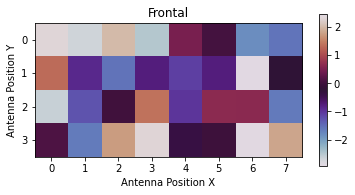

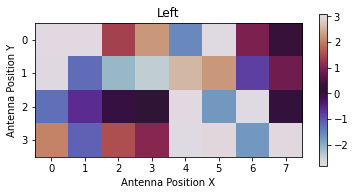

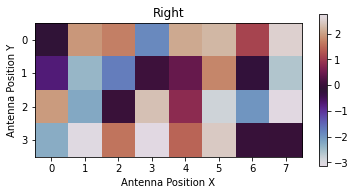

In [22]:
plot_array_phases(points_frontal, 512, 8, "Frontal")
plot_array_phases(points_left, 512, 8, "Left")
plot_array_phases(points_right, 512, 8, "Right")

## Phase and Timing Offset Compensation

### Loading Offsets from the provided JSON file

In [23]:
!wget https://dichasus.inue.uni-stuttgart.de/datasets/data/dichasus-015x/reftx-offsets-dichasus-015x.json -P /home/florian/Downloads/dichasus

--2021-11-25 18:23:41--  https://dichasus.inue.uni-stuttgart.de/datasets/data/dichasus-015x/reftx-offsets-dichasus-015x.json
SSL_INIT
Loaded CA certificate '/etc/ssl/certs/ca-certificates.crt'
Resolving dichasus.inue.uni-stuttgart.de (dichasus.inue.uni-stuttgart.de)... 129.69.175.114
Connecting to dichasus.inue.uni-stuttgart.de (dichasus.inue.uni-stuttgart.de)|129.69.175.114|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1835 (1.8K) [application/json]
Saving to: ‘/home/florian/Downloads/dichasus/reftx-offsets-dichasus-015x.json.2’

reftx-offsets-dicha 100%[===================>]   1.79K  --.-KB/s    in 0s      

2021-11-25 18:23:41 (202 MB/s) - ‘/home/florian/Downloads/dichasus/reftx-offsets-dichasus-015x.json.2’ saved [1835/1835]



In [24]:
offsets = None
with open("/home/florian/Downloads/dichasus/reftx-offsets-dichasus-015x.json", "r") as offsetfile:
    offsets = json.load(offsetfile)

### Visualizing the Phase Correction Terms

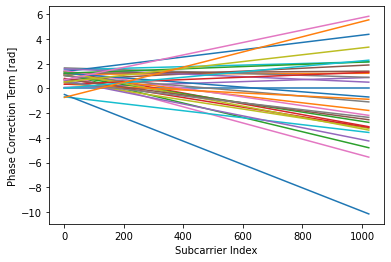

In [25]:
sto_offset = tf.tensordot(tf.constant(offsets["sto"]), 2 * np.pi * tf.range(1024, dtype = np.float32) / 1024.0, axes = 0)
cpo_offset = tf.tensordot(tf.constant(offsets["cpo"]), tf.ones(1024, dtype = np.float32), axes = 0)
correction_phase = (sto_offset + cpo_offset).numpy()
plt.xlabel("Subcarrier Index")
plt.ylabel("Phase Correction Term [rad]")
plt.plot(np.transpose(correction_phase))
plt.show()


### Applying Correction Terms

In [26]:
def apply_calibration(csi, pos):
    sto_offset = tf.tensordot(tf.constant(offsets["sto"]), 2 * np.pi * tf.range(tf.shape(csi)[1], dtype = np.float32) / tf.cast(tf.shape(csi)[1], np.float32), axes = 0)
    cpo_offset = tf.tensordot(tf.constant(offsets["cpo"]), tf.ones(tf.shape(csi)[1], dtype = np.float32), axes = 0)
    csi = tf.multiply(csi, tf.exp(tf.complex(0.0, sto_offset + cpo_offset)))
    return csi, pos

In [27]:
points_left_calibrated = points_left.map(apply_calibration)
points_frontal_calibrated = points_frontal.map(apply_calibration)
points_right_calibrated = points_right.map(apply_calibration)

In [28]:
plot_array_phases(points_left_calibrated, 512, 8)
plot_array_phases(points_frontal_calibrated, 512, 8)
plot_array_phases(points_right_calibrated, 512, 8)

TypeError: plot_array_phases() missing 1 required positional argument: 'title'

## Classical Angle of Arrival (AoA) Estimation

In [17]:
dataset_calibrated = dataset.map(apply_calibration)

In [18]:
antenna_distance = 0.118

def estimate_frequency(samples):
    # Kay's Single Frequency Estimator:
    # S. Kay, "A fast and accurate single frequency estimator" in IEEE Transactions on Acoustics, Speech, and Signal Processing,
    # vol. 37, no. 12, pp. 1987-1990, Dec. 1989, doi: 10.1109/29.45547.
    N = len(samples)
    w = (3 / 2 * N) / (N**2 - 1) * (1 - ((np.arange(0, N - 1) - (N / 2 - 1)) / (N / 2))**2)
    return sum([w[t] * np.angle(np.conj(samples[t]) * samples[t + 1]) for t in np.arange(0, N - 1)])

def estimate_angles(dataset, subcarrier_start, subcarrier_count, fcarrier, bandwidth):
    positions = []
    angle_estimates = []
    
    for csi, pos in dataset:
        subcarriers = csi.shape[1]
        csi_mean = tf.math.reduce_sum(csi[:,subcarrier_start:subcarrier_start + subcarrier_count], axis = 1).numpy()
        wavelength = 299792458 / (fcarrier + bandwidth * (-subcarriers / 2 + subcarrier_start + subcarrier_count / 2) / subcarriers)
        phase_diff = np.mean([estimate_frequency(csi_mean[row]) for row in assignments])
        wavelength_diff = phase_diff * wavelength / antenna_distance / (2 * np.pi)

        angle_estimate = None
        if wavelength_diff <= -1:
            angle_estimate = -np.pi / 2
        elif wavelength_diff >= 1:
            angle_estimate = np.pi / 2
        else:
            angle_estimate = np.arcsin(wavelength_diff)

        positions.append(pos.numpy())
        angle_estimates.append(angle_estimate)
        
    return np.vstack(positions), np.hstack(angle_estimates)

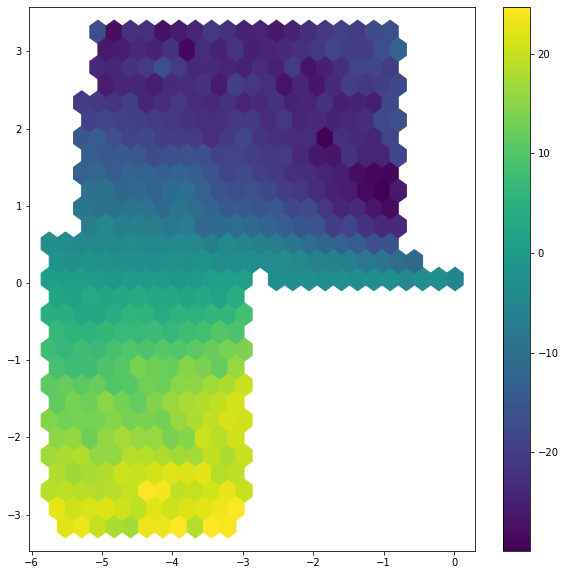

In [19]:
positions, angle_estimates = estimate_angles(dataset_calibrated, 0, 1, 1.272e9, 50e6)

plt.figure(figsize=(10,10))
plt.hexbin(positions[:,0], positions[:,1], C = np.rad2deg(angle_estimates), gridsize = 25)
plt.colorbar()
plt.show()

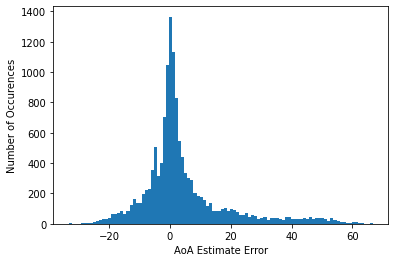

MAE: 8.94328128057288 degrees


In [20]:
true_angles = np.arctan2(-positions[:,1], -positions[:,0] + 0.2)
est_error = np.rad2deg(np.angle(np.exp(1.0j * angle_estimates) * np.conj(np.exp(1.0j * true_angles))))
plt.xlabel("AoA Estimate Error")
plt.ylabel("Number of Occurences")
plt.hist(est_error, bins = 100)
plt.show()

print("MAE:", np.mean(np.abs(est_error)), "degrees")